# From Monocular Depth to Multi-view Point Maps

## Introduction

**SC5006 · Computer Vision & Application · Week 11**  
**Topics:** monocular depth, camera geometry, VGGT, confidence filtering, and a bridge to dynamic/4D Gaussian representations.

In Lab 07, geometry emerged from matched features and optimization. Here you will inspect geometry predicted by pretrained networks. You will run **Depth Anything V2 Small** on a photograph, use **VGGT** to infer cameras, depth and point maps from overlapping views, and reconstruct a coloured point cloud.

By the end, you should be able to:
1. distinguish relative inverse-depth-like output from metric depth;
2. unproject a depth map and transform camera points into world coordinates;
3. compare VGGT's direct point head with its depth-and-camera route;
4. evaluate a confidence/coverage trade-off without confusing agreement with ground-truth accuracy;
5. explain what additional representation and supervision a dynamic 4D model needs.

**Suggested schedule:** 15 min setup; 20 min monocular depth; 25 min geometry; 30 min VGGT and confidence analysis; 20 min evaluation and discussion. Download the weights before class. No fine-tuning is required.

**Prerequisites:** Lab 07 camera conventions, NumPy broadcasting, and basic PyTorch inference.



Run the complete supplied baseline first, then complete Q1–Q5. Tutorial 09 uses the same static fern scene as its companion tutorial. The question groups total 100 points.

### Evaluation metrics

Compare depth-derived and directly predicted point maps in their shared scene coordinates. Report confidence coverage, normalized point-head disagreement, and AbsRel, RMSE and delta1 agreement between aligned model predictions. Real-image scores measure model agreement, not ground-truth accuracy. Known synthetic geometry tests check the formulas separately.

Confidence is an uncalibrated score. Use raw arrays for evaluation; clipped and coloured heat maps are for display. Monocular output and scene geometry do not provide metres without an external scale reference.

## Submission

Please submit:

- Your completed `tutorial09_depth_point_maps_STUDENT.ipynb`, with outputs visible
- `depth_point_maps_baseline_submission.zip`, containing raw predictions and original run records
- `tutorial09_question_results.zip`, containing your report, confidence table, figures and PLY

Keep all `###YOUR CODE HERE###` markers and question numbers. Complete every code and written answer. Total: **100 points**.

| Section | Points |
|---|---:|
| Q1 — Relative depth and visualization | 20 |
| Q2 — Depth to 3D geometry | 25 |
| Q3 — Point maps and confidence | 25 |
| Q4 — Metrics and controlled evaluation | 20 |
| Q5 — Static geometry to 4D/3DGS | 10 |
| **Total** | **100** |

The setup and model baselines are supplied. Student exercise cells intentionally stop with `NotImplementedError` until completed. Marks reward correct geometry, reproducibility and justified interpretation; a denser cloud alone is not evidence of a better reconstruction.


---

## Before starting — runnable tutorial

1. Upload this notebook to Google Colab. Under **Runtime → Change runtime type**, select **GPU**. Use one fresh hosted runtime for this tutorial.
2. Run **Install in this runtime** once. If packages were installed, choose **Runtime → Restart session**, then continue at **Environment check**. The notebook runs in Colab's current runtime; no kernel registration or kernel selection is required.
3. Run the supplied baseline cells in order and **stop before Q1**. Do not use **Run all** on an unfinished student notebook: the exercise placeholders intentionally raise errors.
4. Complete the code and written answers, then run Q1–Q5 in order. Download the completed notebook and both result ZIPs before leaving the session.

The ZIP contains the example photographs; uploading the notebook alone also works because missing photographs are downloaded from the pinned public source. Model weights used by Tutorial 09 are downloaded at first use. A runtime reset may delete local files, so download the generated baseline ZIP before it happens.

After a kernel restart with results still present, run **Restore after a kernel restart**, then the completed questions. After a VM reset, extract your saved baseline ZIP into the new working folder and install dependencies before restoring. Local Jupyter users may run the same installation cell in their current environment, or install the included requirements file.


### Install in this runtime

Use a GPU runtime for the neural baseline. The installation cell pins PyTorch and the model dependencies in the current runtime. Start with **two views**; four views can be selected when memory allows. The MPS/CPU fallback is available for local use.

Run the following cell once. If it changes packages, restart the session and continue at **Environment check**, skipping the installation cell on that restart. Use a fresh runtime for each tutorial.

In [1]:
# Run this cell once in a fresh Colab runtime (or your current Jupyter environment).
import sys, subprocess, json
from importlib import metadata
if not (3, 10) <= sys.version_info[:2] <= (3, 12):
    raise RuntimeError('This pinned lesson environment requires Python 3.10–3.12; use a Colab Python 3.12 runtime.')
PACKAGES = ['torch==2.8.0', 'torchvision==0.23.0', 'numpy==1.26.4', 'matplotlib==3.10.3', 'Pillow==11.2.1', 'opencv-python==4.11.0.86', 'transformers==4.51.3', 'huggingface_hub==0.35.3', 'safetensors==0.6.2', 'accelerate==1.10.1', 'einops==0.8.1']
def installed_version(name):
    try: return metadata.version(name).split('+')[0]
    except metadata.PackageNotFoundError: return None
needs_install = any(installed_version(pin.split('==')[0]) != pin.split('==')[1] for pin in PACKAGES)
if needs_install:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet',
                    '--disable-pip-version-check', '--index-url', 'https://pypi.org/simple',
                    *PACKAGES], check=True)
try:
    origin = json.loads(metadata.distribution('vggt').read_text('direct_url.json') or '{}')
except metadata.PackageNotFoundError:
    origin = {}
if origin.get('vcs_info', {}).get('commit_id') != 'a288dd0f14786c93483e45524328726ab7b1b4ce':
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', '--no-deps',
                    '--disable-pip-version-check', 'git+https://github.com/facebookresearch/vggt.git@a288dd0f14786c93483e45524328726ab7b1b4ce'], check=True)
    needs_install = True
_RESTART_AFTER_INSTALL = needs_install or globals().get('_RESTART_AFTER_INSTALL', False)
if _RESTART_AFTER_INSTALL:
    print('Installation finished. In Colab: Runtime > Restart session; then continue at Environment check below. Skip this installation cell after restarting.')
else:
    print('Pinned packages are already installed. Continue at Environment check.')


Pinned packages are already installed. Continue at Environment check.


### Environment check

After installation and any requested session restart, begin here and continue downward.

In [2]:
if globals().get('_RESTART_AFTER_INSTALL', False):
    raise RuntimeError('Restart the session after installation, then resume at Environment check or recovery.')


import os, gc, json, platform, time
from contextlib import nullcontext
import torch
from transformers import AutoImageProcessor, AutoModelForDepthEstimation
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from accelerate import init_empty_weights
from vggt.models.vggt import VGGT
from vggt.utils.load_fn import load_and_preprocess_images
from vggt.utils.pose_enc import pose_encoding_to_extri_intri

torch.manual_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
if os.environ.get("LAB09_ALLOW_CPU", "0") != "1" and DEVICE.type == "cpu":
    raise RuntimeError(
        "No GPU detected, but this lab needs one: VGGT (~1B parameters) is very slow on CPU.\n"
        "In Colab: Runtime -> Change runtime type -> select a GPU (e.g. T4), then "
        "Runtime -> Restart session, and resume at 'Environment check'.\n"
        "To proceed on CPU anyway (not recommended, much slower), set "
        "os.environ['LAB09_ALLOW_CPU'] = '1' before running this cell."
    )
N_VIEWS = int(os.environ.get("LAB09_FRAMES", "2"))
assert 2 <= N_VIEWS <= 12

def synchronize():
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    elif DEVICE.type == "mps": torch.mps.synchronize()

def release_cache():
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    elif DEVICE.type == "mps": torch.mps.empty_cache()

hardware = {"python": platform.python_version(), "torch": torch.__version__,
            "device": str(DEVICE), "platform": platform.platform(),
            "gpu_name": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else
                        "Apple Silicon GPU (MPS)" if DEVICE.type == "mps" else "CPU",
            "cuda_runtime": torch.version.cuda, "views": N_VIEWS}
print(json.dumps(hardware, indent=2))


{
  "python": "3.12.12",
  "torch": "2.8.0+cu126",
  "device": "cuda",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.35",
  "gpu_name": "Tesla T4",
  "cuda_runtime": "12.6",
  "views": 2
}


### Dataset and shared pixel coordinates

The 12 LLFF fern photographs are the same as in Lab 07. VGGT resizes/crops its selected inputs; its predicted intrinsics refer to those **processed images**, not to the original files. We feed the same processed RGB images to the monocular model so later pixel-wise comparisons use identical coordinates.

The images have no ground-truth depth in this exercise. The synthetic geometry check in Q2 has known values; the real-image experiment in Q4 measures agreement between predictions.


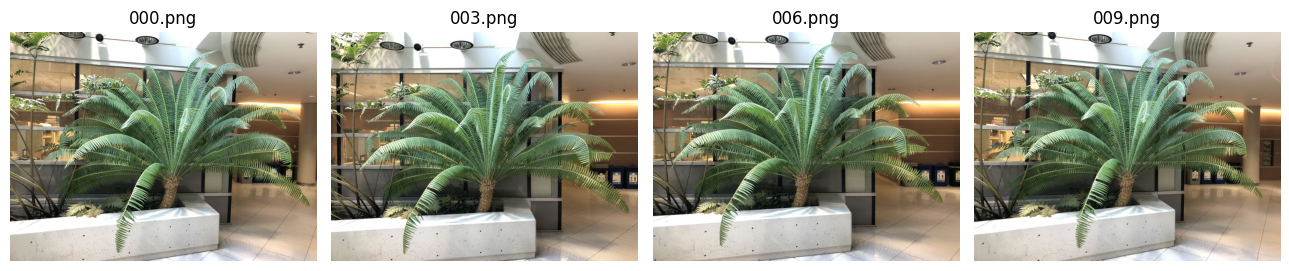

12 real photographs; seed=42; source revision=a288dd0f14786c93483e45524328726ab7b1b4ce


In [3]:
from pathlib import Path
import hashlib, json, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
rng = np.random.default_rng(SEED)
DATA_DIR = Path("data/fern/images")
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_REVISION = "a288dd0f14786c93483e45524328726ab7b1b4ce"
IMAGE_NAMES = [f"{i:03d}.png" for i in range(12)]
data_manifest = []
for name in IMAGE_NAMES:
    url = f"https://raw.githubusercontent.com/facebookresearch/vggt/{DATA_REVISION}/examples/llff_fern/images/{name}"
    path = DATA_DIR / name
    if not path.exists():
        with urllib.request.urlopen(url, timeout=120) as response:
            payload = response.read()
        temporary = path.with_suffix(".download")
        temporary.write_bytes(payload)
        temporary.replace(path)
    with Image.open(path) as image:
        image.verify()
    data_manifest.append({"name": name, "url": url, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
image_paths = [DATA_DIR / name for name in IMAGE_NAMES]
Path("data/fern/manifest.json").write_text(json.dumps(data_manifest, indent=2))
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, path in zip(axes, image_paths[::3]):
    ax.imshow(Image.open(path)); ax.set_title(path.name); ax.axis("off")
plt.tight_layout(); plt.show()
print(f"{len(image_paths)} real photographs; seed={SEED}; source revision={DATA_REVISION}")


In [4]:
OUTPUT = Path("lab09_outputs")
OUTPUT.mkdir(exist_ok=True)
selected_paths = image_paths[:N_VIEWS]
vggt_images_cpu = load_and_preprocess_images([str(p) for p in selected_paths])
S, _, H, W = vggt_images_cpu.shape
assert S == N_VIEWS and H % 14 == 0 and W % 14 == 0
processed_rgb = vggt_images_cpu.permute(0,2,3,1).numpy()
processed_pil = [Image.fromarray(np.clip(image*255,0,255).astype(np.uint8)) for image in processed_rgb]
print("Selected files:", [p.name for p in selected_paths])
print("VGGT tensor shape:", tuple(vggt_images_cpu.shape), "— intrinsics will use this H,W")


from pathlib import Path
import hashlib, json, os, uuid
import numpy as np

def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2))
    temporary.replace(path)

def latest_records(path):
    path = Path(path)
    records = json.loads(path.read_text()) if path.exists() else []
    if not isinstance(records, list):
        raise ValueError(f'Expected a list of run records: {path}')
    by_name = {}
    for row in records:
        if not isinstance(row, dict) or not isinstance(row.get('name'), str):
            raise ValueError(f'Invalid run record: {path}')
        by_name[row['name']] = row
    return list(by_name.values())

def save_record(path, record):
    rows = {row['name']: row for row in latest_records(path)}
    rows[record['name']] = record
    atomic_json(path, list(rows.values()))
    return list(rows.values())

def archive_working_files(destination, directories):
    import zipfile
    destination = Path(destination)
    with zipfile.ZipFile(destination, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for directory in directories:
            directory = Path(directory)
            for path in sorted(directory.rglob('*')):
                if path.is_file() and not path.name.endswith('.tmp'):
                    archive.write(path, path.absolute().relative_to(Path.cwd()))
    print('Saved', destination.name)
    return destination.name

def save_stage(name, arrays, metadata):
    # Commit a new immutable array file before replacing this stage's record.
    array_name = f'{name}_{uuid.uuid4().hex}.npz'
    path = OUTPUT / array_name
    np.savez_compressed(path, **arrays)
    row = dict(name=name, arrays=array_name,
               sha256=hashlib.sha256(path.read_bytes()).hexdigest(), **metadata)
    previous = {r['name']: r for r in latest_records(OUTPUT/'run_records.json')}.get(name)
    save_record(OUTPUT/'run_records.json', row)
    if previous and previous.get('arrays') != array_name:
        old = OUTPUT / previous['arrays']
        if old.parent == OUTPUT and old.is_file():
            old.unlink()
    return row

def load_stage(name, expected_signature=None):
    row = {r['name']: r for r in latest_records(OUTPUT/'run_records.json')}.get(name)
    if row is None or (expected_signature is not None and row['signature'] != expected_signature):
        return None
    path = OUTPUT / row['arrays']
    if not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest() != row['sha256']:
        raise ValueError(f'Missing or damaged {name} arrays. Restore the complete baseline ZIP or rerun this stage.')
    with np.load(path, allow_pickle=False) as saved:
        arrays = {key: saved[key] for key in saved.files}
    return arrays, row

def restore_depth_baseline(work_dir):
    global OUTPUT
    work_dir = Path(work_dir).resolve()
    os.chdir(work_dir)
    OUTPUT = Path('lab09_outputs')
    mono, geometry = load_stage('monocular'), load_stage('vggt')
    if mono is None or geometry is None:
        raise FileNotFoundError('Both stages must be complete. Run the baseline cells; a completed matching stage is reused.')
    mono_arrays, mono_record = mono
    arrays, record = geometry
    if mono_record['signature'] != record['signature']:
        raise ValueError('The two saved stages use different input/configuration settings. Complete a matching baseline first.')
    signature = record['signature']
    depth = arrays['depth_maps']
    s, h, w = depth.shape
    expected_shapes = {'direct_world': (s,h,w,3), 'processed_rgb': (s,h,w,3),
                       'depth_confidence': (s,h,w), 'point_confidence': (s,h,w),
                       'intrinsics': (s,3,3), 'extrinsics': (s,3,4)}
    for key, shape in expected_shapes.items():
        if arrays[key].shape != shape:
            raise ValueError(f'Invalid saved shape for {key}')
    if mono_arrays['mono_relative'].shape != depth.shape:
        raise ValueError('Monocular and VGGT pixel grids differ')
    state = dict(arrays, **mono_arrays, OUTPUT=OUTPUT, S=s, H=h, W=w,
                 N_VIEWS=s, SEED=record['seed'], hardware=record['hardware'],
                 data_manifest=record['input_manifest'],
                 image_paths=[work_dir/'data/fern/images'/r['name'] for r in record['input_manifest']],
                 selected_paths=[work_dir/'data/fern/images'/name for name in signature['input_files']],
                 mono_times=mono_record['seconds'], vggt_seconds=record['seconds'],
                 peak_cuda_gib=record['peak_cuda_GiB'], inference_precision=record['precision'],
                 DA_MODEL=signature['models']['monocular']['id'],
                 DA_REVISION=signature['models']['monocular']['revision'],
                 VGGT_MODEL=signature['models']['vggt']['id'],
                 VGGT_REVISION=signature['models']['vggt']['revision'])
    return state


DA_MODEL = 'depth-anything/Depth-Anything-V2-Small-hf'
DA_REVISION = '5426e4f0f36572d16453bbda7a8389317b1bef99'
VGGT_MODEL = 'facebook/VGGT-1B'
VGGT_REVISION = '860abec7937da0a4c03c41d3c269c366e82abdf9'
baseline_signature = {
    'input_files': [p.name for p in selected_paths],
    'input_hashes': [r['sha256'] for r in data_manifest[:S]],
    'input_shape': [S,3,H,W], 'seed': SEED,
    'models': {'monocular': {'id':DA_MODEL,'revision':DA_REVISION},
               'vggt': {'id':VGGT_MODEL,'revision':VGGT_REVISION,
                        'code_revision':'a288dd0f14786c93483e45524328726ab7b1b4ce'}}}
FORCE_INFERENCE = False  # True deliberately recomputes each stage and replaces its saved record.


Selected files: ['000.png', '001.png']
VGGT tensor shape: (2, 3, 392, 518) — intrinsics will use this H,W


### Runnable baseline — monocular relative depth

Depth Anything V2 Small receives one RGB image at a time. Its relative model produces an inverse-depth-like ordering: larger responses generally indicate nearer surfaces. The numerical values are **not metres** and do not directly specify a valid camera-axis depth map.

Keep the raw floating-point prediction. Percentile normalization is only for displaying a heat map. Loading weights and preprocessing are excluded from the timed inference block; the recorded time covers a first, synchronized forward pass and resizing to the common pixel grid, without a warm-up claim.


Each completed stage is saved immediately. Re-running reuses a matching saved stage and its original timing. Set `FORCE_INFERENCE=True` in the previous cell only when you intentionally want a new measurement.

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/99.2M [00:00<?, ?B/s]

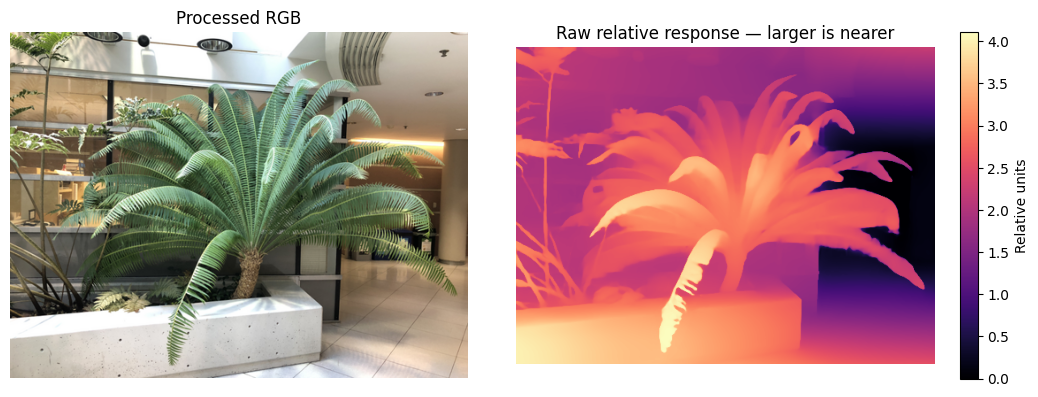

Monocular inference seconds per view: [2.295186188999992, 0.06616248199998154]


In [5]:
cached_mono = None if FORCE_INFERENCE else load_stage('monocular', baseline_signature)
if cached_mono is None:
    processor = AutoImageProcessor.from_pretrained(DA_MODEL, revision=DA_REVISION, use_fast=False)
    mono_model = AutoModelForDepthEstimation.from_pretrained(DA_MODEL, revision=DA_REVISION).to(DEVICE).eval()
    mono_predictions, mono_times = [], []
    for image in processed_pil:
        inputs = processor(images=image, return_tensors="pt").to(DEVICE)
        assert next(mono_model.parameters()).device.type == DEVICE.type
        synchronize(); started = time.perf_counter()
        with torch.inference_mode():
            output = mono_model(**inputs)
            assert output.predicted_depth.device.type == DEVICE.type
            prediction = processor.post_process_depth_estimation(output, target_sizes=[(H,W)])[0]["predicted_depth"]
        synchronize(); mono_times.append(time.perf_counter()-started)
        mono_predictions.append(prediction.float().cpu().numpy())
    mono_relative = np.stack(mono_predictions)
    assert mono_relative.shape == (S,H,W) and np.all(np.isfinite(mono_relative))

    del mono_model, inputs, output, prediction
    release_cache()
    save_stage('monocular', {'mono_relative':mono_relative},
               {'signature':baseline_signature,'seconds':mono_times,'hardware':hardware})
else:
    arrays, record = cached_mono
    mono_relative, mono_times = arrays['mono_relative'], record['seconds']
    print('Reused saved monocular predictions; displayed timings are from the original run.')
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].imshow(processed_rgb[0]); axes[0].set_title("Processed RGB")
im = axes[1].imshow(mono_relative[0], cmap="magma"); axes[1].set_title("Raw relative response — larger is nearer")
fig.colorbar(im, ax=axes[1], label="Relative units")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("Monocular inference seconds per view:", mono_times)

### Runnable baseline — VGGT cameras, depth and point maps

VGGT processes the selected views jointly. We use its camera, depth and point heads; tracking is outside the scope of this lab. Its world coordinate system is shared across this input set, but its distances have no guaranteed metric scale.

Weights are loaded through the `safetensors` format. A meta-device initialization avoids keeping a second random copy of a billion-parameter model in memory. Only the unused tracking-head weights are excluded; all required parameters must match. On CUDA, autocast chooses bfloat16 when supported, otherwise float16. The MPS/CPU reference path uses float32.

We time only the synchronized model forward pass, excluding download, model loading, preprocessing and plotting. This is a first-run measurement, not a throughput benchmark. CUDA peak memory is reported when available.


model.safetensors:   0%|          | 0.00/5.03G [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/vggt/models/vggt.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


{'recorded_device': 'cuda', 'input_shape': [2, 3, 392, 518], 'seconds': 4.538252800000009, 'precision': 'autocast torch.bfloat16', 'peak_cuda_GiB': 6.868499279022217}


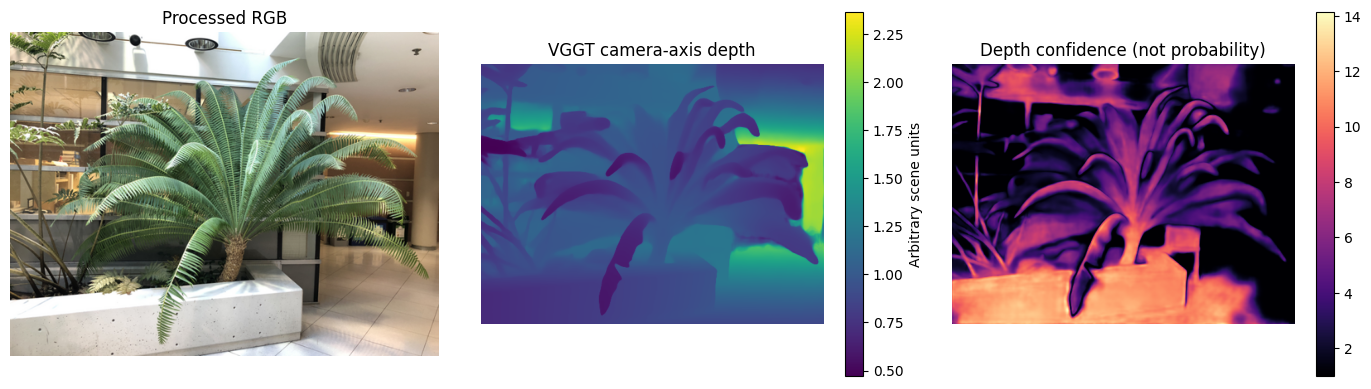

In [6]:
cached_geometry = None if FORCE_INFERENCE else load_stage('vggt', baseline_signature)
if cached_geometry is None:
    checkpoint_path = hf_hub_download(VGGT_MODEL, filename="model.safetensors", revision=VGGT_REVISION)
    with init_empty_weights():
        geometry_model = VGGT(enable_track=False)
    weights = load_file(checkpoint_path, device="cpu")
    weights = {key: value for key,value in weights.items() if not key.startswith("track_head.")}
    geometry_model.load_state_dict(weights, strict=True, assign=True)
    del weights
    # These normalization buffers are not part of the checkpoint.
    geometry_model.aggregator._resnet_mean = torch.tensor([0.485,0.456,0.406]).view(1,1,3,1,1)
    geometry_model.aggregator._resnet_std = torch.tensor([0.229,0.224,0.225]).view(1,1,3,1,1)
    geometry_model = geometry_model.to(DEVICE).eval()
    vggt_images = vggt_images_cpu.to(DEVICE)
    assert next(geometry_model.parameters()).device.type == DEVICE.type
    amp_dtype = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
    autocast_context = torch.autocast("cuda", dtype=amp_dtype) if DEVICE.type == "cuda" else nullcontext()
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    synchronize(); started = time.perf_counter()
    with torch.inference_mode(), autocast_context:
        predictions = geometry_model(vggt_images)
    synchronize(); vggt_seconds = time.perf_counter()-started
    assert predictions["depth"].device.type == DEVICE.type
    peak_cuda_gib = torch.cuda.max_memory_allocated()/2**30 if DEVICE.type == "cuda" else None
    with torch.inference_mode():
        extrinsic_t, intrinsic_t = pose_encoding_to_extri_intri(predictions["pose_enc"].float(), (H,W))
    depth_maps = predictions["depth"][0,...,0].float().cpu().numpy()
    depth_confidence = predictions["depth_conf"][0].float().cpu().numpy()
    direct_world = predictions["world_points"][0].float().cpu().numpy()
    point_confidence = predictions["world_points_conf"][0].float().cpu().numpy()
    extrinsics = extrinsic_t[0].float().cpu().numpy()
    intrinsics = intrinsic_t[0].float().cpu().numpy()
    assert depth_maps.shape == (S,H,W) and direct_world.shape == (S,H,W,3)
    assert np.all(np.isfinite(depth_maps)) and np.all(depth_maps>0)
    assert np.all(np.isfinite(direct_world))

    inference_precision = "autocast "+str(amp_dtype) if DEVICE.type=="cuda" else "float32"
    del geometry_model,predictions,vggt_images,extrinsic_t,intrinsic_t
    release_cache()
    save_stage('vggt', {'depth_maps':depth_maps,'depth_confidence':depth_confidence,
               'direct_world':direct_world,'point_confidence':point_confidence,
               'intrinsics':intrinsics,'extrinsics':extrinsics,'processed_rgb':processed_rgb},
               {'signature':baseline_signature,'seconds':vggt_seconds,'hardware':hardware,
                'seed':SEED,'input_manifest':data_manifest,'precision':inference_precision,
                'peak_cuda_GiB':peak_cuda_gib})
else:
    arrays, record = cached_geometry
    globals().update(arrays)
    hardware, vggt_seconds = record['hardware'], record['seconds']
    inference_precision, peak_cuda_gib = record['precision'], record['peak_cuda_GiB']
    print('Reused saved VGGT predictions; hardware and timings describe the original run.')
print({'recorded_device':hardware['device'],'input_shape':[S,3,H,W],
       'seconds':vggt_seconds,'precision':inference_precision,'peak_cuda_GiB':peak_cuda_gib})
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].imshow(processed_rgb[0]);axes[0].set_title("Processed RGB")
im=axes[1].imshow(depth_maps[0],cmap="viridis");axes[1].set_title("VGGT camera-axis depth")
fig.colorbar(im,ax=axes[1],label="Arbitrary scene units")
im=axes[2].imshow(depth_confidence[0],cmap="magma");axes[2].set_title("Depth confidence (not probability)")
fig.colorbar(im,ax=axes[2])
for ax in axes:ax.axis("off")
plt.tight_layout();plt.show()

### Save the baseline

Download this ZIP before ending the session. It stores both stages, their original timings and the shared image coordinates. The questions use these saved arrays and do not need the model weights to be loaded again.

In [7]:
archive_working_files('depth_point_maps_baseline_submission.zip', [OUTPUT, Path('data/fern')])

Saved depth_point_maps_baseline_submission.zip


'depth_point_maps_baseline_submission.zip'

### Restore after a kernel restart

After a kernel restart, run **only the next cell**, then your completed Q1–Q5 cells in order. It restores the original arrays, camera parameters, confidence maps, input list, hardware and timings from disk. No model loading, download or inference is performed.

Keep the entire `lab09_outputs/` folder or extract the baseline ZIP into `WORK_DIR`. If only the monocular stage finished, run the baseline cells instead: the completed matching stage is reused and only the unfinished stage runs. Changed images or view counts require a matching baseline. The saved records contain one row per stage, even after rerunning.

In [8]:
if globals().get('_RESTART_AFTER_INSTALL', False):
    raise RuntimeError('Restart the session after installation, then resume at Environment check or recovery.')

from pathlib import Path
import hashlib, json, os, uuid
import numpy as np

def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2))
    temporary.replace(path)

def latest_records(path):
    path = Path(path)
    records = json.loads(path.read_text()) if path.exists() else []
    if not isinstance(records, list):
        raise ValueError(f'Expected a list of run records: {path}')
    by_name = {}
    for row in records:
        if not isinstance(row, dict) or not isinstance(row.get('name'), str):
            raise ValueError(f'Invalid run record: {path}')
        by_name[row['name']] = row
    return list(by_name.values())

def save_record(path, record):
    rows = {row['name']: row for row in latest_records(path)}
    rows[record['name']] = record
    atomic_json(path, list(rows.values()))
    return list(rows.values())

def archive_working_files(destination, directories):
    import zipfile
    destination = Path(destination)
    with zipfile.ZipFile(destination, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for directory in directories:
            directory = Path(directory)
            for path in sorted(directory.rglob('*')):
                if path.is_file() and not path.name.endswith('.tmp'):
                    archive.write(path, path.absolute().relative_to(Path.cwd()))
    print('Saved', destination.name)
    return destination.name

def save_stage(name, arrays, metadata):
    # Commit a new immutable array file before replacing this stage's record.
    array_name = f'{name}_{uuid.uuid4().hex}.npz'
    path = OUTPUT / array_name
    np.savez_compressed(path, **arrays)
    row = dict(name=name, arrays=array_name,
               sha256=hashlib.sha256(path.read_bytes()).hexdigest(), **metadata)
    previous = {r['name']: r for r in latest_records(OUTPUT/'run_records.json')}.get(name)
    save_record(OUTPUT/'run_records.json', row)
    if previous and previous.get('arrays') != array_name:
        old = OUTPUT / previous['arrays']
        if old.parent == OUTPUT and old.is_file():
            old.unlink()
    return row

def load_stage(name, expected_signature=None):
    row = {r['name']: r for r in latest_records(OUTPUT/'run_records.json')}.get(name)
    if row is None or (expected_signature is not None and row['signature'] != expected_signature):
        return None
    path = OUTPUT / row['arrays']
    if not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest() != row['sha256']:
        raise ValueError(f'Missing or damaged {name} arrays. Restore the complete baseline ZIP or rerun this stage.')
    with np.load(path, allow_pickle=False) as saved:
        arrays = {key: saved[key] for key in saved.files}
    return arrays, row

def restore_depth_baseline(work_dir):
    global OUTPUT
    work_dir = Path(work_dir).resolve()
    os.chdir(work_dir)
    OUTPUT = Path('lab09_outputs')
    mono, geometry = load_stage('monocular'), load_stage('vggt')
    if mono is None or geometry is None:
        raise FileNotFoundError('Both stages must be complete. Run the baseline cells; a completed matching stage is reused.')
    mono_arrays, mono_record = mono
    arrays, record = geometry
    if mono_record['signature'] != record['signature']:
        raise ValueError('The two saved stages use different input/configuration settings. Complete a matching baseline first.')
    signature = record['signature']
    depth = arrays['depth_maps']
    s, h, w = depth.shape
    expected_shapes = {'direct_world': (s,h,w,3), 'processed_rgb': (s,h,w,3),
                       'depth_confidence': (s,h,w), 'point_confidence': (s,h,w),
                       'intrinsics': (s,3,3), 'extrinsics': (s,3,4)}
    for key, shape in expected_shapes.items():
        if arrays[key].shape != shape:
            raise ValueError(f'Invalid saved shape for {key}')
    if mono_arrays['mono_relative'].shape != depth.shape:
        raise ValueError('Monocular and VGGT pixel grids differ')
    state = dict(arrays, **mono_arrays, OUTPUT=OUTPUT, S=s, H=h, W=w,
                 N_VIEWS=s, SEED=record['seed'], hardware=record['hardware'],
                 data_manifest=record['input_manifest'],
                 image_paths=[work_dir/'data/fern/images'/r['name'] for r in record['input_manifest']],
                 selected_paths=[work_dir/'data/fern/images'/name for name in signature['input_files']],
                 mono_times=mono_record['seconds'], vggt_seconds=record['seconds'],
                 peak_cuda_gib=record['peak_cuda_GiB'], inference_precision=record['precision'],
                 DA_MODEL=signature['models']['monocular']['id'],
                 DA_REVISION=signature['models']['monocular']['revision'],
                 VGGT_MODEL=signature['models']['vggt']['id'],
                 VGGT_REVISION=signature['models']['vggt']['revision'])
    return state


# Change WORK_DIR to the folder where you extracted the baseline ZIP.
import matplotlib.pyplot as plt
from PIL import Image
WORK_DIR = Path.cwd()
os.chdir(WORK_DIR)
globals().update(restore_depth_baseline(WORK_DIR))
print('Restored raw depth, point maps, confidence, cameras, RGB and original inference records. Continue with Q1–Q5.')

Restored raw depth, point maps, confidence, cameras, RGB and original inference records. Continue with Q1–Q5.


## Q1 — Relative depth and visualization (20 points)

### Q1.1 Robust visualization (8 points)
Implement a 2nd–98th percentile normalization over finite entries of one prediction map. Clip valid values to [0,1], map invalid values to 0, and return all zeros for a constant or entirely invalid map. Do not modify the original floating-point array.


In [9]:
QOUT = Path('tutorial09_question_results'); QOUT.mkdir(exist_ok=True)

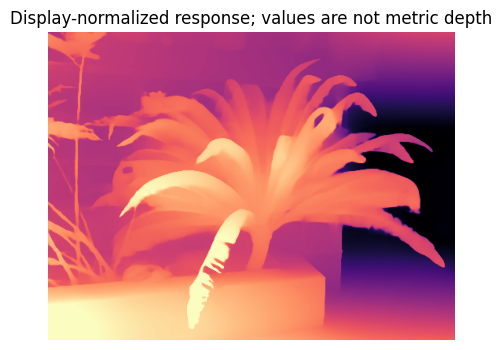

In [10]:
def normalize_for_display(values, lower=2, upper=98):
    ###YOUR CODE HERE###
    values = np.asarray(values, dtype=float)          # read-only use: the raw array is never modified
    finite = np.isfinite(values)
    display = np.zeros(values.shape)                   # invalid pixels stay 0
    if not finite.any():
        return display                                 # entirely invalid map
    lo, hi = np.percentile(values[finite], [lower, upper])
    if hi <= lo:
        return display                                 # constant map: nothing to show
    display[finite] = np.clip((values[finite] - lo) / (hi - lo), 0, 1)
    return display

assert np.all(normalize_for_display(np.ones((3,3))) == 0)
assert np.all(normalize_for_display(np.full((2,2),np.nan)) == 0)
plt.figure(figsize=(7,4)); plt.imshow(normalize_for_display(mono_relative[0]), cmap="magma")
plt.title("Display-normalized response; values are not metric depth"); plt.axis("off"); plt.savefig(QOUT/'figure_19.png', dpi=140, bbox_inches='tight'); plt.show()

### Q1.2 What does a depth image mean? (12 points)
Answer all three parts (4 points each):
1. Why is an 8-bit heat map unsuitable for quantitative depth evaluation?
2. Why is `1 / relative_response` not automatically metric depth? Describe scale and shift ambiguity in an inverse-depth representation.
3. If the RGB image is cropped or resized, what must happen to the focal lengths and principal point before unprojection?


**Your answer:**

**1. Why an 8-bit heat map can't be used for evaluation.**
A heat map is made for the eye, not for measuring. To draw it we (a) clip to the 2nd–98th percentile, so the extremes are flattened, (b) rescale *each image on its own*, so the same colour means different depths in different images, and (c) squeeze everything into 256 levels, then pass it through a non-linear colour map. The original numbers can't be recovered from it, so any error computed on it measures the picture, not the model. We always evaluate the raw float array.

**2. Why `1 / relative_response` is not metric depth.**
Depth Anything V2 (relative) is trained with a scale-and-shift-invariant loss, so its output is only *affinely* related to true inverse depth:
$r \approx a\cdot\frac{1}{z} + b$, with an unknown $a>0$ and $b$ for every image.
- **Scale $a$:** stretches the whole scene — a small room and a big hall can give the same output.
- **Shift $b$:** worse — $1/r = 1/(a/z + b)$, so the shift bends near and far depths *differently*. It is not just a global zoom; it changes the shape of the scene. $r$ can even be ≤ 0, where $1/r$ is meaningless.

To get metres we need an outside reference (a known object size, LiDAR / SfM points, or a metric model) to solve for $a$ and $b$. In Q4.2 we fit $a,b$ against VGGT — but VGGT has no metric scale either, so the result is still in arbitrary scene units.

**3. Cropping / resizing and the intrinsics.**
$K$ must describe *the exact image we unproject*.
- **Resize** by $s_x = W_{new}/W_{old}$, $s_y = H_{new}/H_{old}$: $f_x' = s_x f_x,\; c_x' = s_x c_x$ and $f_y' = s_y f_y,\; c_y' = s_y c_y$ (with a pixel-centre convention: $c' = s(c+0.5)-0.5$).
- **Crop** with top-left corner $(x_0, y_0)$: focal lengths stay the same, the principal point moves: $c_x' = c_x - x_0,\; c_y' = c_y - y_0$.
- Apply these in the same order as the image operations. Using the original $K$ on a resized/cropped image puts every 3D point on the wrong ray.

In this notebook VGGT already returns $K$ for its processed (resized/cropped) images, and we ran Depth Anything on those same processed images, so every map shares one pixel grid.

## Q2 — Depth to 3D geometry (25 points)

Now assume a true camera-axis depth $z$ and known pinhole intrinsics:
$$K=\begin{bmatrix}f_x&0&c_x\\0&f_y&c_y\\0&0&1\end{bmatrix},\quad
X_c(u,v)=z(u,v)K^{-1}[u,v,1]^\top.$$
Camera-axis depth is the z-coordinate, not the Euclidean distance from the camera centre.

### Q2.1 Unproject a depth image (15 points)
Implement an `(H,W) → (H,W,3)` unprojection using integer pixel centres `(u,v)` and a finite, zero-skew K. Reject nonpositive focal lengths and invalid input shapes. Put `NaN` in points whose input depth is non-finite or not positive. The following synthetic depth image has actual known geometry.


In [11]:
def unproject_depth(depth, K):
    ###YOUR CODE HERE###
    depth, K = np.asarray(depth, dtype=float), np.asarray(K, dtype=float)
    if depth.ndim != 2:
        raise ValueError("depth must be an (H,W) array")
    if K.shape != (3,3) or not np.all(np.isfinite(K)):
        raise ValueError("K must be a finite 3x3 matrix")
    if not (np.isclose(K[0,1], 0) and np.allclose(K[1,0], 0) and np.allclose(K[2], [0,0,1])):
        raise ValueError("K must be a zero-skew pinhole matrix")
    fx, fy, cx, cy = K[0,0], K[1,1], K[0,2], K[1,2]
    if fx <= 0 or fy <= 0:
        raise ValueError("focal lengths must be positive")
    v, u = np.indices(depth.shape, dtype=float)                     # v = row, u = column (pixel centres)
    z = np.where(np.isfinite(depth) & (depth > 0), depth, np.nan)   # invalid depth -> NaN point
    return np.stack([(u - cx) / fx * z, (v - cy) / fy * z, z], axis=-1)   # X_c = z * K^-1 [u,v,1]

toy_K = np.array([[2.,0,1.],[0,2.,1.],[0,0,1.]])
toy_depth = np.full((3,3),2.)
toy_camera = unproject_depth(toy_depth,toy_K)
assert np.allclose(toy_camera[1,1], [0,0,2])
assert np.allclose(toy_camera[0,0], [-1,-1,2])
assert np.allclose(toy_camera[2,2], [1,1,2])
print("Top-left / centre / bottom-right:",toy_camera[0,0],toy_camera[1,1],toy_camera[2,2])

Top-left / centre / bottom-right: [-1. -1.  2.] [0. 0. 2.] [1. 1. 2.]


### Q2.2 Transform camera points into world points (10 points)
The extrinsic matrix is camera-from-world: $X_c=RX_w+t$. Implement its inverse for an arbitrary `(...,3)` array. Use a nonidentity rotation in the supplied round-trip test, which catches a mistaken transpose. Return points with the same shape as the input.


In [12]:
def camera_to_world(camera_points, extrinsic):
    ###YOUR CODE HERE###
    points, extrinsic = np.asarray(camera_points, dtype=float), np.asarray(extrinsic, dtype=float)
    if points.shape[-1] != 3 or extrinsic.shape != (3,4):
        raise ValueError("expected (...,3) points and a (3,4) extrinsic")
    R, t = extrinsic[:, :3], extrinsic[:, 3]
    # X_c = R X_w + t  =>  X_w = R^T (X_c - t). With points as rows this is (X_c - t) @ R.
    return (points - t) @ R

angle = np.deg2rad(30)
toy_R = np.array([[np.cos(angle),0,np.sin(angle)],[0,1,0],[-np.sin(angle),0,np.cos(angle)]])
toy_t = np.array([0.3,-0.2,0.5])
toy_extrinsic = np.column_stack([toy_R,toy_t])
toy_world = camera_to_world(toy_camera,toy_extrinsic)
assert toy_world.shape == toy_camera.shape
assert np.allclose(toy_world @ toy_R.T + toy_t, toy_camera, atol=1e-10)
print("Camera/world round trip passed.")

Camera/world round trip passed.


## Q3 — Point maps and confidence (25 points)

### Q3.1 Confidence filtering (10 points)
Implement a mask selecting finite points with positive finite camera depth and a finite confidence score at or above quantile `q`. Compute the threshold over otherwise valid pixels across the whole input set. Return `(mask, threshold)`. Reject an out-of-range q or an empty valid set.

Use **depth confidence** with depth-derived points and **point confidence** with the direct point head. Their score scales are not interchangeable. A quantile is a selection rule, not a calibrated probability of correctness.


In [13]:
def confidence_mask(points, depth, confidence, q=0.5):
    ###YOUR CODE HERE###
    if not 0 <= q <= 1:
        raise ValueError("q must be in [0, 1]")
    points, depth, confidence = (np.asarray(a, dtype=float) for a in (points, depth, confidence))
    if points.shape != depth.shape + (3,) or confidence.shape != depth.shape:
        raise ValueError("points must be (...,3) and match depth/confidence")
    valid = (np.isfinite(points).all(axis=-1) & np.isfinite(depth) & (depth > 0)
             & np.isfinite(confidence))
    if not valid.any():
        raise ValueError("no valid pixels")
    threshold = float(np.quantile(confidence[valid], q))   # one threshold for the whole input set
    return valid & (confidence >= threshold), threshold

depth_world=np.stack([camera_to_world(unproject_depth(z,K),E) for z,K,E in zip(depth_maps,intrinsics,extrinsics)])
keep,threshold=confidence_mask(depth_world,depth_maps,depth_confidence,q=0.5)
assert keep.shape == depth_maps.shape and keep.any()
print({"threshold":threshold,"retained_pixels":int(keep.sum()),"coverage":float(keep.mean())})

{'threshold': 3.4502393007278442, 'retained_pixels': 203056, 'coverage': 0.5}


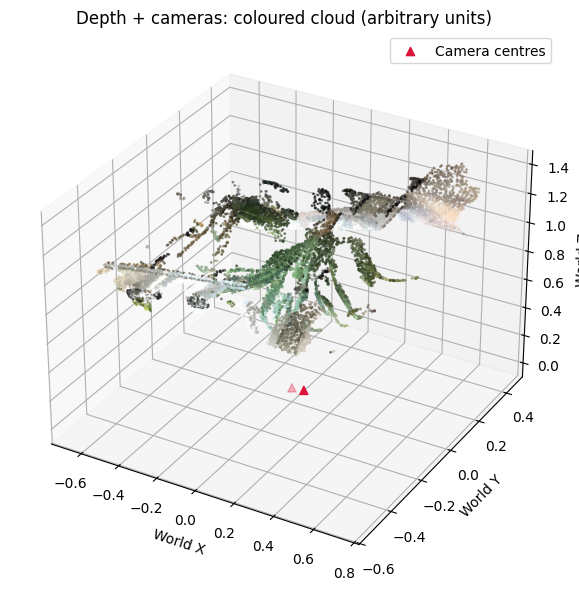

In [14]:
# Provided visualization/export helpers: the assessed geometry is in your functions above.
def show_cloud(points, colours, mask, title, max_points=15000):
    xyz, rgb=points[mask],colours[mask]
    if not len(xyz): raise ValueError("Empty point cloud")
    ids=np.random.default_rng(SEED).choice(len(xyz),min(max_points,len(xyz)),replace=False)
    fig=plt.figure(figsize=(9,6));ax=fig.add_subplot(111,projection="3d")
    ax.scatter(*xyz[ids].T,c=rgb[ids],s=1,alpha=0.6)
    centres=np.stack([-E[:,:3].T@E[:,3] for E in extrinsics])
    ax.scatter(*centres.T,c="crimson",marker="^",s=35,label="Camera centres")
    ax.set(xlabel="World X",ylabel="World Y",zlabel="World Z",title=title)
    ax.legend();plt.tight_layout();plt.savefig(QOUT/'figure_28.png', dpi=140, bbox_inches='tight'); plt.show()

def export_ply(path, points, colours, mask):
    xyz=points[mask];rgb=np.clip(colours[mask]*255,0,255).astype(np.uint8)
    with open(path,"w") as stream:
        stream.write("ply\nformat ascii 1.0\nelement vertex %d\n" % len(xyz))
        stream.write("property float x\nproperty float y\nproperty float z\n")
        stream.write("property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n")
        np.savetxt(stream,np.column_stack([xyz,rgb]),fmt="%.6f %.6f %.6f %d %d %d")

show_cloud(depth_world,processed_rgb,keep,"Depth + cameras: coloured cloud (arbitrary units)")
export_ply(OUTPUT/"vggt_depth_cloud.ply",depth_world,processed_rgb,keep)


### Q3.2 Two routes to a point map (10 points)
Calculate per-pixel Euclidean disagreement between the direct point head and your unprojected depth route. Divide by the median positive depth of all valid pixels to form one scale-normalized diagnostic. Report its median and 90th percentile on pixels retained by both heads at their own median-confidence thresholds.

Both heads use the same scene coordinate system. Do not fit a new per-pixel transform or independent alignment between them. Small disagreement is **self-consistency**, not evidence of correct physical geometry.


Normalized head disagreement: {'median': 0.003992778829030265, 'p90': 0.00931141241809847, 'pixels': 164401, 'median_depth_scale': 0.9369753003120422}


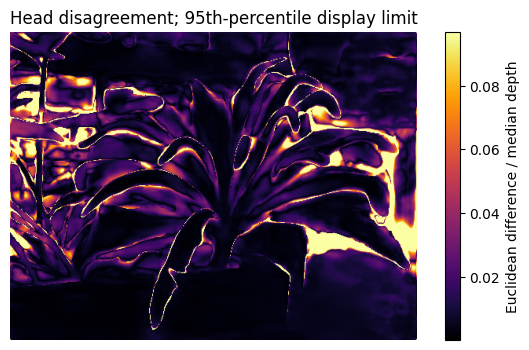

In [15]:
def point_map_disagreement(direct, from_depth, depths, mask):
    ###YOUR CODE HERE###
    distance = np.linalg.norm(np.asarray(direct, float) - np.asarray(from_depth, float), axis=-1)
    valid_depth = np.isfinite(depths) & (depths > 0)
    if not valid_depth.any():
        raise ValueError("no valid depth to normalise by")
    scale = float(np.median(depths[valid_depth]))       # one scene-level scale, no per-pixel fitting
    disagreement = distance / scale
    selected = disagreement[mask]
    if selected.size == 0 or not np.all(np.isfinite(selected)):
        raise ValueError("mask is empty or contains invalid points")
    summary = {"median": float(np.median(selected)), "p90": float(np.quantile(selected, 0.9)),
               "pixels": int(selected.size), "median_depth_scale": scale}
    return disagreement, summary

direct_camera_depth=np.stack([(points@E[:,:3].T+E[:,3])[...,2] for points,E in zip(direct_world,extrinsics)])
point_keep,_=confidence_mask(direct_world,direct_camera_depth,point_confidence,q=0.5)
joint_keep=keep&point_keep
disagreement,point_agreement=point_map_disagreement(direct_world,depth_world,depth_maps,joint_keep)
print("Normalized head disagreement:",point_agreement)
plt.figure(figsize=(7,4));plt.imshow(disagreement[0],cmap="inferno",vmax=np.quantile(disagreement[0],0.95))
plt.colorbar(label="Euclidean difference / median depth");plt.title("Head disagreement; 95th-percentile display limit")
plt.axis("off");plt.savefig(QOUT/'figure_30.png', dpi=140, bbox_inches='tight'); plt.show()

### Q3.3 Interpreting confidence (5 points)
Why can confidence filtering produce a cleaner picture while discarding important surfaces? Identify two difficult regions in your plots. Explain why a confidence value of 2 does not mean a 200% chance of correctness.


**Your answer:**

**Cleaner picture, but surfaces are lost.** Filtering keeps the pixels the network is most sure about. These are usually well-textured, seen clearly in both views and away from object edges. Dropping the rest removes noisy "flying" points, so the cloud *looks* neater. But low confidence isn't the same as unimportant: it usually marks exactly the **hard geometry**. Cutting it leaves holes and biases the cloud towards easy surfaces. A neater cloud is not a more complete or more correct one.

**Two difficult regions in my plots** (dark in the depth-confidence map, bright in the head-disagreement map):
1. **Edges of the fronds and the gaps between them.** Depth jumps from leaf to background here, so a pixel mixes both and its depth lands *between* them, creating "flying" points. Confidence drops along every frond outline, and these outlines are the brightest lines in the disagreement map.
2. **The far right side: the brightly lit glass/wall and the shiny floor tiles below it.** Over-exposed, reflective surfaces look different from each view and show reflections rather than a fixed surface, so there's little reliable multi-view evidence. Confidence is almost black there, and the two heads disagree strongly. By contrast, the textured concrete planter in the foreground gets *high* confidence: texture plus nearness make it easy.

**Why "confidence = 2" is not "200 % correct".** VGGT's confidence is **not a probability**. It is a positive weight (computed as $1+e^{x}$, so it ranges from 1 to ∞), learned with an uncertainty loss of the form $c\cdot\text{error} - \alpha\log c$. It has no units and is **uncalibrated**: it only *ranks* pixels (higher means the model expects a smaller error). The depth and point heads even use different scales. To read it as a probability, you would have to calibrate it against ground truth. That's why we threshold by a **quantile** (keep the top x %) rather than a fixed value.

## Q4 — Metrics and controlled evaluation (20 points)

### Q4.1 Implement depth metrics (10 points)
For positive reference depth $z$ and prediction $\hat z$, implement:
$$\mathrm{AbsRel}=\mathrm{mean}(|\hat z-z|/z),\quad
\mathrm{RMSE}=\sqrt{\mathrm{mean}((\hat z-z)^2)},\quad
\delta_1=\mathrm{mean}(\max(\hat z/z,z/\hat z)<1.25).$$
Use only a supplied mask with finite positive reference values. Raise an error for an empty evaluation set or invalid predictions at evaluated pixels, rather than silently dropping difficult predictions. The exact synthetic check below is a correctness test, not a benchmark result.


In [16]:
def depth_metrics(prediction, reference, mask):
    ###YOUR CODE HERE###
    prediction, reference = np.asarray(prediction, float), np.asarray(reference, float)
    mask = np.asarray(mask, bool)
    if not prediction.shape == reference.shape == mask.shape:
        raise ValueError("prediction, reference and mask must have the same shape")
    evaluated = mask & np.isfinite(reference) & (reference > 0)
    if not evaluated.any():
        raise ValueError("empty evaluation set")
    z, z_hat = reference[evaluated], prediction[evaluated]
    if not np.all(np.isfinite(z_hat) & (z_hat > 0)):
        raise ValueError("invalid predictions at evaluated pixels")   # never drop hard pixels silently
    return {"abs_rel": float(np.mean(np.abs(z_hat - z) / z)),
            "rmse": float(np.sqrt(np.mean((z_hat - z) ** 2))),
            "delta1": float(np.mean(np.maximum(z_hat / z, z / z_hat) < 1.25)),
            "n": int(evaluated.sum())}

toy_metrics=depth_metrics(np.array([1.,2.,4.]),np.array([1.,2.,2.]),np.ones(3,bool))
assert np.isclose(toy_metrics["abs_rel"],1/3)
assert np.isclose(toy_metrics["rmse"],np.sqrt(4/3))
assert np.isclose(toy_metrics["delta1"],2/3)
print("Synthetic metric check:",toy_metrics)

Synthetic metric check: {'abs_rel': 0.3333333333333333, 'rmse': 1.1547005383792515, 'delta1': 0.6666666666666666, 'n': 3}


### Q4.2 Confidence/coverage experiment (10 points)

We have no metric ground truth. The following supplied calibration fits one affine relationship per image between the monocular response and **VGGT inverse depth**, on alternating checkerboard pixels. The other pixels are held out for agreement measurement. This is a within-image diagnostic, not an independent test set or a metric-depth calibration. The fit is computed once and kept fixed across all confidence thresholds.

Evaluate `q = 0, 0.5, 0.9` on the held-out pixels (6 points). Report retained coverage, all three depth-agreement metrics, and point-head disagreement. Then discuss the trade-off using the actual table (4 points). A smaller error on a smaller selected set does not imply better full-image accuracy. Record the number of inverse-depth values clipped to a small positive value; they must not be silently excluded from the metrics.


In [17]:
yy,xx=np.indices((H,W))
calibration_pixels=(xx+yy)%2==0
evaluation_pixels=~calibration_pixels
assert not np.any(calibration_pixels&evaluation_pixels)
aligned_mono_depth=np.empty_like(depth_maps)
alignment_details=[]
for s in range(S):
    valid=np.isfinite(mono_relative[s])&np.isfinite(depth_maps[s])&(depth_maps[s]>0)
    fit=valid&calibration_pixels
    A=np.column_stack([mono_relative[s][fit],np.ones(fit.sum())])
    target_inverse=1/depth_maps[s][fit]
    if np.linalg.matrix_rank(A)<2:raise ValueError("Degenerate inverse-depth calibration")
    a,b=np.linalg.lstsq(A,target_inverse,rcond=None)[0]
    inverse_prediction=a*mono_relative[s]+b
    floor=1e-4*float(np.median(target_inverse))
    clipped=inverse_prediction<=floor
    aligned_mono_depth[s]=1/np.maximum(inverse_prediction,floor)
    alignment_details.append({"view":selected_paths[s].name,"scale":float(a),"shift":float(b),
                              "clipped_pixels":int(clipped.sum()),"calibration_pixels":int(fit.sum())})
print("Affine inverse-depth calibration:",json.dumps(alignment_details,indent=2))


Affine inverse-depth calibration: [
  {
    "view": "000.png",
    "scale": 0.16957415227937625,
    "shift": 0.6939401903281506,
    "clipped_pixels": 0,
    "calibration_pixels": 101528
  },
  {
    "view": "001.png",
    "scale": 0.15529067931092483,
    "shift": 0.7179438089485822,
    "clipped_pixels": 0,
    "calibration_pixels": 101528
  }
]


In [18]:
###YOUR CODE HERE###
comparison=[]
# Pixels whose fitted inverse depth was clipped to the floor (same rule as the calibration cell).
# They stay in the metrics; we only count them.
clipped_mask=np.zeros(depth_maps.shape,bool)
for s,d in enumerate(alignment_details):
    fit=calibration_pixels&np.isfinite(mono_relative[s])&np.isfinite(depth_maps[s])&(depth_maps[s]>0)
    clipped_mask[s]=np.float64(d["scale"])*mono_relative[s]+np.float64(d["shift"])<=1e-4*float(np.median(1/depth_maps[s][fit]))
assert clipped_mask.sum()==sum(d["clipped_pixels"] for d in alignment_details)

heldout=np.broadcast_to(evaluation_pixels,depth_maps.shape)
for q in (0.0,0.5,0.9):
    # Depth confidence selects pixels for the depth route; the affine fit above stays fixed.
    depth_keep,depth_threshold=confidence_mask(depth_world,depth_maps,depth_confidence,q=q)
    selected=depth_keep&heldout
    comparison.append({"quantile":q,"confidence_threshold":depth_threshold,
                       "heldout_coverage":float(selected.sum()/heldout.sum()),
                       **depth_metrics(aligned_mono_depth,depth_maps,selected),
                       "median_head_disagreement":float(np.median(disagreement[selected])),
                       "clipped_in_selection":int((clipped_mask&selected).sum())})

print(f"{'q':>4} {'coverage':>10} {'AbsRel':>10} {'RMSE*':>10} {'delta1':>10} {'head diff':>10}")
for r in comparison:
    print(f"{r['quantile']:4.1f} {r['heldout_coverage']:10.3f} {r['abs_rel']:10.4f} "
          f"{r['rmse']:10.4f} {r['delta1']:10.4f} {r['median_head_disagreement']:10.4f}")
print("*RMSE in VGGT scene units. All rows measure model agreement, not ground-truth accuracy.")
print("Clipped inverse-depth pixels kept inside each row:",[r["clipped_in_selection"] for r in comparison])
first,last=comparison[0],comparison[-1]
print(f"Summary q=0 -> q=0.9: coverage {first['heldout_coverage']:.0%} -> {last['heldout_coverage']:.0%}, "
      f"AbsRel {first['abs_rel']:.3f} -> {last['abs_rel']:.3f}, delta1 {first['delta1']:.3f} -> {last['delta1']:.3f}, "
      f"head disagreement {first['median_head_disagreement']:.4f} -> {last['median_head_disagreement']:.4f}")

   q   coverage     AbsRel      RMSE*     delta1  head diff
 0.0      1.000     0.1373     0.2113     0.8518     0.0077
 0.5      0.500     0.0846     0.0942     0.9739     0.0045
 0.9      0.100     0.0419     0.0449     1.0000     0.0027
*RMSE in VGGT scene units. All rows measure model agreement, not ground-truth accuracy.
Clipped inverse-depth pixels kept inside each row: [0, 0, 0]
Summary q=0 -> q=0.9: coverage 100% -> 10%, AbsRel 0.137 -> 0.042, delta1 0.852 -> 1.000, head disagreement 0.0077 -> 0.0027


**Your answer:**

**What the table shows.** Raising q from 0 to 0.9 keeps fewer held-out pixels: coverage drops from 100 % to about 10 %. On the kept pixels, monocular and VGGT depth agree more: AbsRel goes from 0.137 to 0.042, δ1 from 0.852 to 1.000, and the two VGGT heads also agree more (median head disagreement 0.0077 → 0.0027). The middle row (q = 0.5: AbsRel 0.085, δ1 0.974) sits in between, so the trend is steady, not a fluke of one threshold. Confidence therefore ranks pixels sensibly: confident pixels are the ones the models agree on.

**The trade-off.**
- **Better numbers on a smaller, easier set.** At q = 0.9 we only score the 10 % "easy" pixels (textured, central, far from edges). The error there is lower *because the hard pixels were removed*, not because the model got better. The full-image quality is still the q = 0 row.
- **Coverage vs. reliability.** For a dense map or rendering, q = 0 or a mild q = 0.5 keeps the scene complete. For something that must be reliable (e.g. initial points for 3DGS or SfM), a high q gives cleaner but sparser points. You always report coverage *next to* the error.
- **Fair comparison.** The affine fit is computed once on the calibration checkerboard and kept fixed, and every row is scored on held-out pixels only, so the rows differ only in the selection. Clipped inverse-depth pixels (none in my run: 0 / 0 / 0) stay inside the metrics. `depth_metrics` raises instead of silently dropping bad predictions.
- **Agreement ≠ accuracy.** VGGT is the reference here, not ground truth. Two models can agree and both be wrong, so these numbers show *self-consistency only*. RMSE is in VGGT's arbitrary scene units, not metres.

## Q5 — From static geometry to 4D / feed-forward 3DGS (10 points)

The Week 11 lecture also introduces dynamic and feed-forward Gaussian representations. This notebook validates static geometry inference; the following design question makes the connection without claiming to implement a 4D reconstruction model.

1. A person moves between the views. Explain why merging the static point maps can create duplicated or stretched geometry (4 points).
2. Name the attributes needed to turn a point into a renderable 3D Gaussian, and describe one way to make the scene time-dependent (4 points).
3. Propose one temporal evaluation and distinguish feed-forward inference from per-scene optimization (2 points).


**Your answer:**

**1. Why a moving person breaks static merging.**
Each point map assumes one static world: every pixel is a 3D point that *never moves*. If the person is at place A in view 1 and place B in view 2, then merging the per-view clouds gives **two copies** of the person (ghosts). And because VGGT reasons jointly over views, it tries to explain the conflict with one static shape. Matching pixels on the person don't agree on a single 3D point, so their depth lands somewhere in between and gets **smeared / stretched along the viewing rays**. If the moving part is large, it can even pull the camera estimate off. The static-scene assumption is broken, so static fusion is wrong.

**2. From a point to a renderable (and time-varying) Gaussian.**
A 3D Gaussian needs:
- **position / mean** $\mu$ (our 3D point),
- **shape:** a covariance, stored as a **3D scale + rotation (quaternion)**,
- **opacity** $\alpha$,
- **colour:** RGB or **spherical-harmonic coefficients** (view-dependent colour).

To make it time-dependent: keep one **canonical** set of Gaussians plus a **deformation field** $D(\mu, t) \rightarrow (\Delta\mu, \Delta\text{rotation}, \Delta\text{scale})$, e.g. a small MLP or HexPlane (as in 4D-GS / Deformable 3DGS). Another option is to give each Gaussian its own motion trajectory over time. Opacity can also vary with $t$ so things can appear or disappear.

**3. Temporal evaluation, and feed-forward vs per-scene.**
- **Evaluation:** hold out time steps *and* a camera. Render those unseen (view, time) pairs and report PSNR / SSIM / LPIPS per frame, plus a **temporal-consistency** score (e.g. flow-warped error between consecutive rendered frames to catch flicker, or 3D tracking error of points over time).
- **Feed-forward** (like VGGT here, or pixelSplat / MVSplat): a network trained once on many scenes predicts the geometry/Gaussians in **one forward pass**, in seconds, with no training on the new scene. **Per-scene optimization** (classic 3DGS / 4DGS): start from points and run thousands of gradient steps on *this* scene's photos with a rendering loss. That takes minutes to hours and gives more detail, but it must be redone for every scene and has seen its training views, so it must be tested on held-out ones.

### Export question results

Run after completing Q1–Q5. The result ZIP includes raw arrays, metrics, the confidence table, a PLY and saved figures. Written answers remain in your completed notebook.

In [19]:
np.savez_compressed(OUTPUT/"predictions.npz",mono_relative=mono_relative,depth=depth_maps,
                    direct_world=direct_world,depth_world=depth_world,depth_confidence=depth_confidence,
                    point_confidence=point_confidence,intrinsics=intrinsics,extrinsics=extrinsics,
                    selected_mask=keep,rgb=processed_rgb)
report={"lab":9,"seed":SEED,"hardware":hardware,"input_files":[p.name for p in selected_paths],
        "input_shape":[S,3,H,W],"input_manifest":data_manifest,
        "models":{"monocular":{"id":DA_MODEL,"revision":DA_REVISION},
                  "vggt":{"id":VGGT_MODEL,"revision":VGGT_REVISION,
                          "code_revision":"a288dd0f14786c93483e45524328726ab7b1b4ce"}},
        "monocular_inference_seconds":mono_times,"vggt_inference_seconds":vggt_seconds,
        "peak_cuda_GiB":peak_cuda_gib,"precision":inference_precision,
        "finite_depth_fraction":float(np.isfinite(depth_maps).mean()),
        "positive_depth_fraction":float((depth_maps>0).mean()),
        "finite_direct_point_fraction":float(np.isfinite(direct_world).all(axis=-1).mean()),
        "exported_points":int(keep.sum()),"head_agreement":point_agreement,
        "alignment":alignment_details,"confidence_comparison":comparison,
        "coordinate_convention":"OpenCV camera-from-world; arbitrary common scene scale",
        "evaluation_note":"Synthetic checks use known geometry. Real-image metrics measure prediction agreement, not ground-truth accuracy."}
(OUTPUT/"report.json").write_text(json.dumps(report,indent=2))
print("Saved",OUTPUT/"report.json",OUTPUT/"predictions.npz",OUTPUT/"vggt_depth_cloud.ply")

import csv, shutil
for name in ('report.json','predictions.npz','vggt_depth_cloud.ply'):
    shutil.copy2(OUTPUT/name, QOUT/name)
with (QOUT/'confidence_comparison.csv').open('w', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(comparison[0]))
    writer.writeheader(); writer.writerows(comparison)
archive_working_files('tutorial09_question_results.zip', [QOUT])

Saved lab09_outputs/report.json lab09_outputs/predictions.npz lab09_outputs/vggt_depth_cloud.ply
Saved tutorial09_question_results.zip


'tutorial09_question_results.zip'

### References and troubleshooting

- [Depth Anything V2 project](https://github.com/DepthAnything/Depth-Anything-V2) and [the pinned Transformers API](https://huggingface.co/docs/transformers/v4.51.3/en/model_doc/depth_anything_v2).
- [VGGT paper](https://arxiv.org/abs/2503.11651), [official code](https://github.com/facebookresearch/vggt), [checkpoint and license](https://huggingface.co/facebook/VGGT-1B).
- [COLMAP pose conventions](https://colmap.github.io/format.html) and [3D Gaussian Splatting](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/).

**Out of memory:** restart the kernel and use 2 views; avoid keeping both models resident. **Wrong-looking cloud:** check axis-depth versus range, camera-from-world inversion, and processed-image intrinsics. **Different numbers across devices:** record precision and device; floating-point inference need not be bitwise identical. **Good-looking image but poor metrics:** verify raw arrays, scale/alignment and evaluation masks. **No network:** pre-cache pinned public weights/images before the session. Respect the upstream code, data and checkpoint licenses when redistributing them.
